In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv('../data/raw/telco_churn.csv')
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors='coerce')

print(df["TotalCharges"].isna().sum())

11


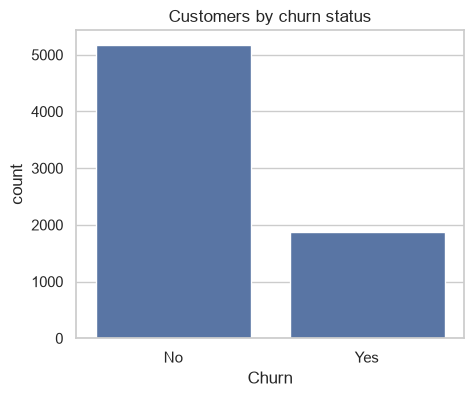

In [3]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customers by churn status")
plt.show()

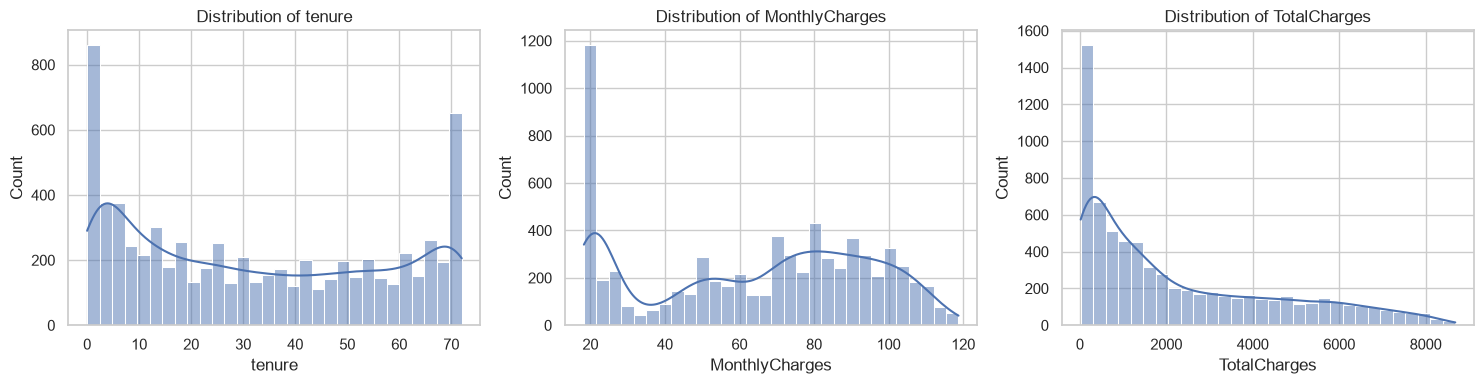

In [4]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

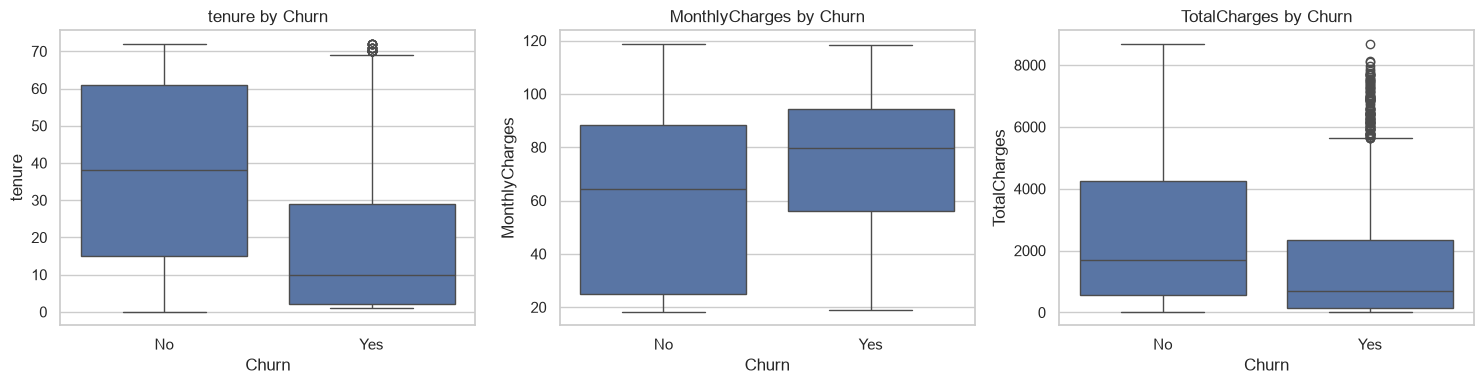

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1683.60
Yes,10.0,79.650,703.55


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=col, ax=ax)
    ax.set_title(f"{col} by Churn")

plt.tight_layout()
plt.show()

df.groupby("Churn")[num_cols].median()

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: ChurnFlag, dtype: float64


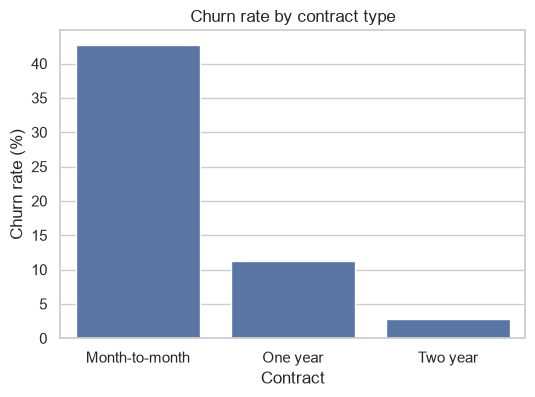

In [5]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

contract_rate = df.groupby("Contract")["ChurnFlag"].mean() * 100
print(contract_rate)

plt.figure(figsize=(6, 4))
sns.barplot(x=contract_rate.index, y=contract_rate.values)
plt.ylabel("Churn rate (%)")
plt.title("Churn rate by contract type")
plt.show()

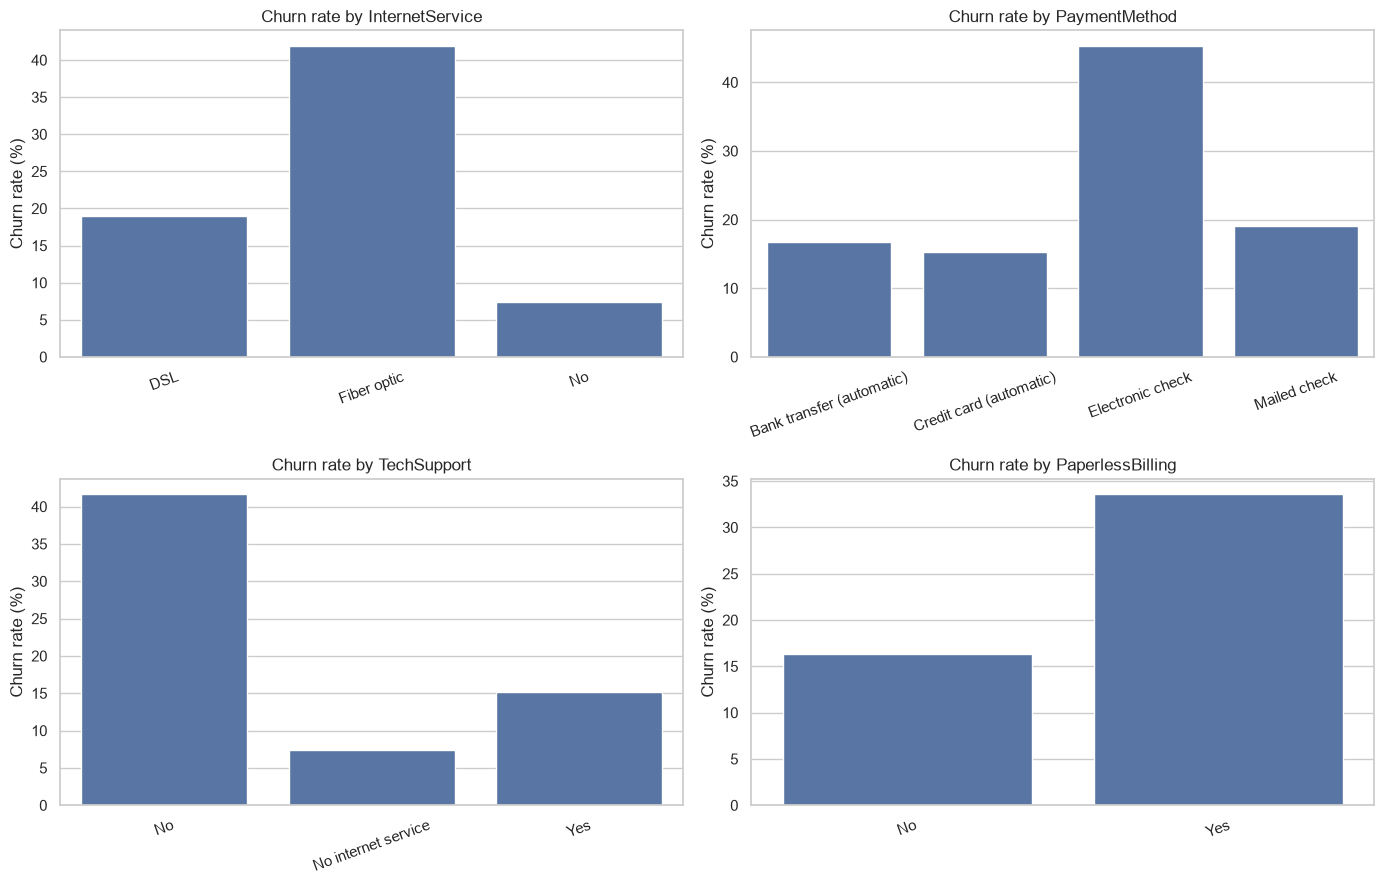

In [8]:
cat_cols = ["InternetService", "PaymentMethod", "TechSupport", "PaperlessBilling"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), cat_cols):
    rate = df.groupby(col)["ChurnFlag"].mean() * 100
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

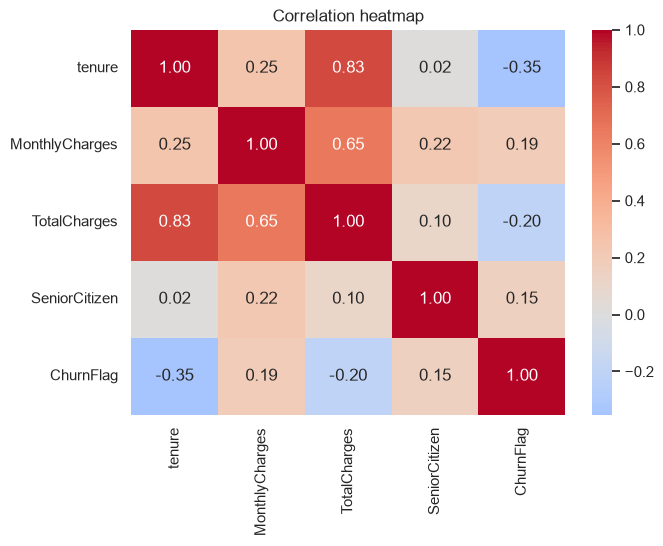

In [6]:
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "ChurnFlag"]
corr = df[corr_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()